# Estadística descriptiva 

## Matrícula de Educación Superior, Región de Tarapacá (2021)
Variable cualitativa: `TIPO DE INSTITUCION` · Variable cuantitativa: `EDAD`

## Objetivo del análisis

**Objetivo general:** pendiente

**Objetivos específicos**

1. **– Descripción general del conjunto de datos**
   - Describir la variable cualitativa `Tipo de institución` (tablas de frecuencia y gráfico).
   - Describir la variable cuantitativa `Edad` (frecuencias, tendencia central, percentiles, dispersión, forma de la distribución y valores atípicos).
   - Analizarlas en conjunto (edad según tipo de institución) y agregar otros resúmenes útiles.
2. **– Preguntas de investigación**
   - ¿Hay áreas del conocimiento con carreras más caras? (con criterio propio de comparación).

   - ¿Qué influencia tiene la edad en el tipo de institución a la que ingresan los estudiantes?

   - ¿Hay carreras con aranceles sustantivamente más caros que la mayoría? ¿Qué lo explica, considerando el contexto regional?

**Flujo de trabajo**

`Base de datos → Exploración → Tipo de institución (frecuencias + gráfico + interpretación) → Edad (frecuencias + gráfico + media/mediana/moda + percentiles + dispersión) → Análisis conjunto → Interpretación → Preguntas del Ítem 2→ Conclusiones`


## 0. Configuración

**Importacion de las librerias ocupadas para la realizacion del trabajo** 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Carga y exploración inicial

**Lectura de la hoja `02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx` del Excel, muestra dimensiones, tipos de dato y las primeras filas. Esto permite entender qué representa cada fila antes de calcular nada.** 

In [2]:
df = pd.read_excel("02_MATRICULAS_ED_SUPERIOR_TARAPACA_2021.xlsx")
df.head() 

,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,250,Femenino,27,25 a 29,2012,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique
1,257,Femenino,24,20 a 24,2021,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Administracion y Comercio,10,0,10,173000,2797000,Tarapaca,Iquique,Iquique
2,430,Masculino,19,15 a 19,2021,Primer semestre,Institutos Profesionales,IP INACAP,ACREDITADA,11/12/2016 AL 11/12/2022,...,Carreras Profesionales,Tecnologia,8,0,8,250000,2426000,Tarapaca,Iquique,Iquique
3,657,Femenino,33,30 a 34,2020,Primer semestre,Universidades Privadas,UNIVERSIDAD SANTO TOMAS,ACREDITADA,31/03/2021 AL 31/03/2025,...,Carreras Profesionales,Derecho,11,1,12,105000,3275000,Tarapaca,Iquique,Iquique
4,801,Masculino,34,30 a 34,2005,Primer semestre,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,ACREDITADA,21/12/2017 AL 21/12/2021,...,Carreras Profesionales,Derecho,10,0,10,161000,2898000,Tarapaca,Iquique,Iquique


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15459 entries, 0 to 15458
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   ID                                       15459 non-null  int64  
 1   GENERO                                   15459 non-null  str    
 2   EDAD                                     15459 non-null  int64  
 3   RANGO EDAD                               15459 non-null  str    
 4   AÑO INGRESO                              15459 non-null  int64  
 5   SEMESTRE INGRESO                         15459 non-null  str    
 6   TIPO DE INSTITUCION                      15459 non-null  str    
 7   NOMBRE DE INSTITUCION                    15459 non-null  str    
 8   ACREDITACION INSTITUCIONAL               15459 non-null  str    
 9   PERIODO DE ACREDITACION                  14066 non-null  str    
 10  AÑOS DE ACREDITACION                     14066 non-null  

In [4]:
df.describe()

,ID,EDAD,AÑO INGRESO,AÑOS DE ACREDITACION,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS)
count,1.545900e+04,15459.000000,15459.000000,14066.000000,15459.000000,15459.000000,15459.000000,15459.000000,1.545900e+04
mean,5.212847e+05,25.963128,2019.199690,4.677520,7.857623,0.135390,7.887509,150122.863704,2.337360e+06
std,3.015266e+05,7.408592,1.990379,0.973858,2.369394,0.375676,2.389942,64479.768674,7.290064e+05
min,2.500000e+02,17.000000,1990.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000e+00
25%,2.620395e+05,21.000000,2018.000000,4.000000,5.000000,0.000000,5.000000,93000.000000,1.914000e+06
50%,5.157640e+05,24.000000,2020.000000,4.000000,8.000000,0.000000,8.000000,155000.000000,2.170000e+06
75%,7.794625e+05,29.000000,2021.000000,5.000000,10.000000,0.000000,10.000000,166000.000000,2.775000e+06
max,1.048496e+06,74.000000,2021.000000,7.000000,12.000000,2.000000,12.000000,250000.000000,4.847000e+06


La base de datos contiene **15.459 registros**. En general, se observa que la edad promedio de los estudiantes es de **25,96 años**, con una desviación estándar de **7,41 años**. La edad mínima registrada es de **17 años** y la máxima de **74 años**.

Respecto al año de ingreso, el promedio es aproximadamente **2019**, mientras que los valores se encuentran entre **1990 y 2021**. En cuanto a la duración de las carreras, la duración total promedio es de aproximadamente **7,89 semestres**, con un mínimo de 1 y un máximo de 12 semestres.

En relación con los valores económicos, la matrícula presenta un promedio de aproximadamente **$150.123**, mientras que el arancel promedio es de **$2.337.360**. La mediana del arancel es de **$2.170.000**, lo que indica que el 50% de los registros presenta un arancel igual o inferior a este valor. Además, el arancel presenta valores desde **$0 hasta $4.847.000**, mostrando una diferencia importante entre los valores registrados.

Finalmente, se observa que algunas variables presentan valores faltantes, como la duración del plan de estudio, donde existen **14.066 registros válidos de los 15.459**. Esta información será considerada en los análisis posteriores.


## 2 Variable cualitativa: `TIPO DE INSTITUCION`

### Registro de estudiante por cada tipo de Instutucion

In [5]:
df.groupby("TIPO DE INSTITUCION").agg({
    "EDAD": ["count", "mean", "median", "min", "max"],
    "VALOR MATRICULA (PESOS)": ["mean", "median"],
    "VALOR ARANCEL (PESOS)": ["mean", "median"],
    "DURACION TOTAL CARRERA (SEMESTRES)": ["mean", "median"]
})

EDAD                            \
                             count       mean median min max   
TIPO DE INSTITUCION                                            
Centros de Formacion Tecnica  3115  26.785233   24.0  18  62   
Institutos Profesionales      3118  25.887107   23.0  18  62   
Universidades CRUCH           6644  25.333835   23.0  17  74   
Universidades Privadas        2582  26.682417   24.0  17  73   

                             VALOR MATRICULA (PESOS)            \
                                                mean    median   
TIPO DE INSTITUCION                                              
Centros de Formacion Tecnica           115318.138042   64000.0   
Institutos Profesionales               179848.941629  250000.0   
Universidades CRUCH                    152453.988561  161000.0   
Universidades Privadas                 150216.905500  134000.0   

                             VALOR ARANCEL (PESOS)             \
                                              mean     median   
TIPO DE INSTITUCION                                             
Centros de Formacion Tecnica          1.710470e+06  1627000.0   
Institutos Profesionales              2.126910e+06  2112000.0   
Universidades CRUCH                   2.610995e+06  2684000.0   
Universidades Privadas                2.643677e+06  3167000.0   

                             DURACION TOTAL CARRERA (SEMESTRES)         
                                                           mean median  
TIPO DE INSTITUCION                                                     
Centros de Formacion Tecnica                           4.758587    5.0  
Institutos Profesionales                               7.876844    8.0  
Universidades CRUCH                                    8.967640   10.0  
Universidades Privadas                                 8.895817   10.0

Se observa que la edad promedio es similar entre las instituciones, variando entre 25,33 y 26,79 años. Los Institutos Profesionales presentan la matrícula promedio más alta ($179.849), mientras que los CFT tienen la más baja ($115.318).

En cuanto al arancel, las Universidades Privadas presentan el promedio más alto ($2.643.677) y los CFT el más bajo ($1.710.470).

Respecto a la duración de las carreras, los CFT tienen el promedio menor (4,76 semestres), mientras que las Universidades CRUCH presentan el mayor (8,97 semestres).

En general, las universidades presentan carreras más largas y aranceles más elevados, mientras que los CFT presentan carreras más cortas y económicas.

In [6]:
tf_tipo_inst = df["TIPO DE INSTITUCION"].value_counts().to_frame()

tf_tipo_inst.columns = ["Frecuencia absoluta"]

tf_tipo_inst["Frecuencia relativa (%)"] = (
    tf_tipo_inst["Frecuencia absoluta"] / len(df) * 100
).round(2)

tf_tipo_inst

,Frecuencia absoluta,Frecuencia relativa (%)
TIPO DE INSTITUCION,,
Universidades CRUCH,6644,42.98
Institutos Profesionales,3118,20.17
Centros de Formacion Tecnica,3115,20.15
Universidades Privadas,2582,16.70


### 2- Gráfico de matriculados por tipo de institución

#### 2.2 Distribución de estudiantes matriculados por tipo de institución  Región de Tarapacá, 2021

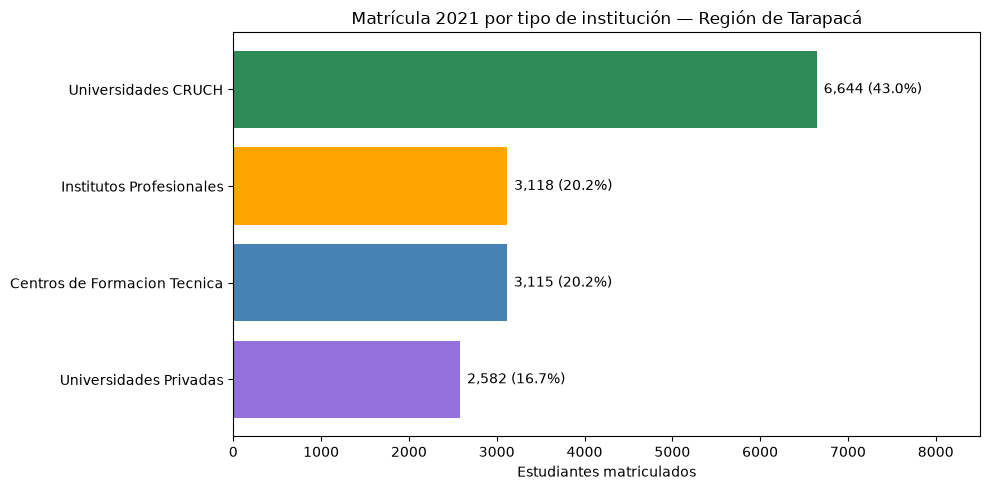

In [7]:
colores = {
    "Centros de Formacion Tecnica": "steelblue",
    "Institutos Profesionales": "orange",
    "Universidades CRUCH": "seagreen",
    "Universidades Privadas": "mediumpurple"
}

f = df["TIPO DE INSTITUCION"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    f.index[::-1],
    f.values[::-1],
    color=[colores[t] for t in f.index[::-1]]
)

for i, v in enumerate(f.values[::-1]):
    ax.text(v + 80, i, f"{v:,} ({v / len(df):.1%})", va="center")

ax.set_xlim(0, f.max() * 1.28)
ax.set_xlabel("Estudiantes matriculados")
ax.set_title("Matrícula 2021 por tipo de institución — Región de Tarapacá")
media = df["VALOR MATRICULA (PESOS)"].mean()
mediana = df["VALOR MATRICULA (PESOS)"].median()

plt.tight_layout()
plt.show()



#### Interpretación Tipo de institución

1. **Mayor representación:**
   Las **Universidades CRUCH** concentran la mayor cantidad, con **6.644 estudiantes (42,98 %)**, siendo la **moda**.

2. **Participación de las universidades:**
   Las **Universidades CRUCH** y **Universidades Privadas** reúnen en conjunto el **59,68 %** de los estudiantes.

3. **Participación de instituciones no universitarias:**
   Los **Institutos Profesionales** y **Centros de Formación Técnica** representan en conjunto el **40,32 %**.

4. **Cantidades similares:**
   Los **Institutos Profesionales** cuentan con **3.118 estudiantes (20,17 %)** y los **Centros de Formación Técnica** con **3.115 (20,15 %)**, presentando una diferencia de solo **3 estudiantes**.

5. **Menor representación:**
   Las **Universidades Privadas** presentan la menor cantidad, con **2.582 estudiantes (16,70 %)**.


#### 2.3 Tablas de frecuencia con más de una variable

**Qué hace este bloque:** cruza `TIPO DE INSTITUCION` con (a) la institución específica, (b) el género y (c) el nivel de carrera. Los porcentajes se calculan **por fila**: dentro de cada tipo, qué proporción corresponde a cada categoría.

In [8]:
tabla_cruzada = (
    df.groupby([
        "TIPO DE INSTITUCION",
        "NOMBRE DE INSTITUCION",
        "NIVEL CARRERA"
    ])
    .size()
    .reset_index(name="Frecuencia")
)

tabla_cruzada["Porcentaje (%)"] = (
    tabla_cruzada["Frecuencia"] /
    tabla_cruzada.groupby("TIPO DE INSTITUCION")["Frecuencia"].transform("sum") * 100
).round(2)

tabla_cruzada

,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,NIVEL CARRERA,Frecuencia,Porcentaje (%)
0,Centros de Formacion Tecnica,CFT DE LA REGION DE TARAPACA,Carreras Tecnicas,968,31.08
1,Centros de Formacion Tecnica,CFT INACAP,Carreras Tecnicas,933,29.95
2,Centros de Formacion Tecnica,CFT SANTO TOMAS,Carreras Tecnicas,1214,38.97
3,Institutos Profesionales,IP INACAP,Carreras Profesionales,1769,56.74
4,Institutos Profesionales,IP SANTO TOMAS,Carreras Profesionales,1291,41.40
5,Institutos Profesionales,IP SANTO TOMAS,Carreras Tecnicas,58,1.86
6,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,Carreras Profesionales,4127,62.12
7,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,Carreras Tecnicas,1206,18.15
8,Universidades CRUCH,UNIVERSIDAD ARTURO PRAT,Magister,116,1.75
9,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,Carreras Profesionales,1195,17.99


### Interpretación tablas con más de una variable

Centros de Formación Técnica: CFT Santo Tomás concentra la mayor proporción (38,97 %), seguido por CFT de la Región de Tarapacá (31,08 %) y CFT INACAP (29,95 %). Todos corresponden a Carreras Técnicas.
Institutos Profesionales: IP INACAP concentra el 56,74 %, seguido por IP Santo Tomás (43,26 %). Predominan las Carreras Profesionales.
Universidades CRUCH: la Universidad Arturo Prat concentra la mayor proporción (82,02 %), principalmente en Carreras Profesionales (62,12 %). La Universidad de Tarapacá representa el 17,99 %.
Universidades Privadas: Universidad Santo Tomás concentra la mayor proporción (61,66 %), principalmente en Carreras Profesionales (60,81 %). Le siguen Universidad Tecnológica de Chile INACAP (21,88 %) y Universidad Bolivariana (16,46 %).

En general, los Centros de Formación Técnica se concentran en Carreras Técnicas, mientras que en los Institutos Profesionales y universidades predominan las Carreras Profesionales.

## 3. Variable cuantitativa: `EDAD`

#### 3.1 Frecuencia absoluta de la variable `EDAD`


In [9]:
frecuencia = df["EDAD"].value_counts().sort_index()
frecuencia

EDAD
17       2
18     380
19    2024
20     826
21    1630
22    1515
23    1257
24    1578
25     371
26     727
27     563
28     511
29     639
30     170
31     353
32     319
33     324
34     406
35      92
36     196
37     188
38     184
39     209
40      65
41     137
42     102
43      92
44      70
45      80
46      61
47      66
48      66
49      33
50      53
51      29
52      25
53      24
54      18
55      16
56       9
57      14
58       9
59       7
60       3
61       5
62       3
63       2
64       1
65       1
69       1
70       1
73       1
74       1
Name: count, dtype: int64

#### 3.2 Tabla de frecuencia de la variable `EDAD` , primero vamos a definir los intervalos de edad para agrupar los datos. Luego, crearemos una tabla de frecuencia que muestre la cantidad de estudiantes en cada intervalo de edad, así como la frecuencia relativa y acumulada.  

In [10]:
k = int(np.ceil(1 + np.log2(len(df))))

rango = df["EDAD"].max() - df["EDAD"].min()
amplitud = np.ceil(rango / k)

bins = np.arange(
    df["EDAD"].min(),
    df["EDAD"].max() + amplitud + 1,
    amplitud
)

df["RANGO EDAD"] = pd.cut(df["EDAD"], bins=bins, right=False)

frecuencia = df["RANGO EDAD"].value_counts().sort_index()

tabla_frecuencia = pd.DataFrame({
    "Frecuencia absoluta (fi)": frecuencia,
    "Frecuencia acumulada (Fi)": frecuencia.cumsum(),
    "Frecuencia relativa % (hi)": frecuencia / frecuencia.sum() * 100,
    "Frecuencia relativa acumulada % (Hi)": 
        (frecuencia / frecuencia.sum()).cumsum() * 100
})

tabla_frecuencia.round(2)

,Frecuencia absoluta (fi),Frecuencia acumulada (Fi),Frecuencia relativa % (hi),Frecuencia relativa acumulada % (Hi)
RANGO EDAD,,,,
"[17.0, 21.0)",3232,3232,20.91,20.91
"[21.0, 25.0)",5980,9212,38.68,59.59
"[25.0, 29.0)",2172,11384,14.05,73.64
"[29.0, 33.0)",1481,12865,9.58,83.22
"[33.0, 37.0)",1018,13883,6.59,89.81
"[37.0, 41.0)",646,14529,4.18,93.98
"[41.0, 45.0)",401,14930,2.59,96.58
"[45.0, 49.0)",273,15203,1.77,98.34
"[49.0, 53.0)",140,15343,0.91,99.25


#### 3.3 Grafico de la distibucion de la `EDAD` de los estudiantes matriculados


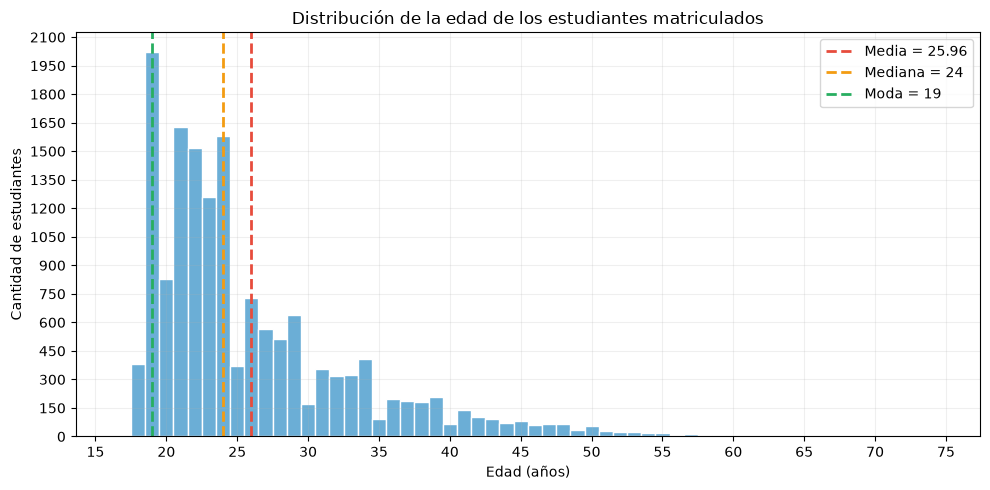

In [12]:
grafico_edad = df["EDAD"]

media = grafico_edad.mean()
mediana = grafico_edad.median()
moda = grafico_edad.mode().iloc[0]

plt.figure(figsize=(10, 5))

plt.hist(
    grafico_edad,
    bins=np.arange(16.5, 75.5, 1),
    color="#6BAED6",
    edgecolor="white"
)

plt.axvline(
    media, color="#E74C3C", linestyle="--",
    linewidth=2, label=f"Media = {media:.2f}"
)

plt.axvline(
    mediana, color="#F39C12", linestyle="--",
    linewidth=2, label=f"Mediana = {mediana:.0f}"
)

plt.axvline(
    moda, color="#27AE60", linestyle="--",
    linewidth=2, label=f"Moda = {moda}"
)

plt.xticks(np.arange(15, 76, 5))
plt.yticks(np.arange(0, grafico_edad.value_counts().max() + 150, 150))

plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de estudiantes")
plt.title("Distribución de la edad de los estudiantes matriculados")

plt.legend()

plt.grid(axis="y", alpha=0.2)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

#### Espacio para resumen e interpretacion

### 3.4 Tendencia central, percentiles, dispersión

calcula: medidas de tendencia central (media, mediana, moda ), percentiles, medidas de dispersión (rango, rango intercuartílico, varianza, desviación estándar, coeficiente de variación), (f) frecuencia por edad simple entre 17 y 30 años para revisar la forma fina de la distribución.

In [13]:
q1, q3 = grafico_edad.quantile([.25, .75])
iqr = q3 - q1

tabla_estadisticas = pd.DataFrame({
    "Categoría": [
        "Tendencia central", "Tendencia central", "Tendencia central",
        "Percentiles", "Percentiles", "Percentiles",
        "Dispersión", "Dispersión", "Dispersión", "Dispersión",
        "Dispersión", "Dispersión", "Dispersión"
    ],

    "Medida": [
        "Media", "Mediana", "Moda",
        "P25 (Q1)", "P50 (Mediana)", "P75 (Q3)",
        "Mínimo", "Máximo", "Rango", "Rango Intercuartílico",
        "Varianza", "Desviación estándar", "Coeficiente de variación (%)"
    ],

    "Valor": [
        grafico_edad.mean(),
        grafico_edad.median(),
        grafico_edad.mode().iloc[0],

        grafico_edad.quantile(.25),
        grafico_edad.quantile(.50),
        grafico_edad.quantile(.75),

        grafico_edad.min(),
        grafico_edad.max(),
        grafico_edad.max() - grafico_edad.min(),
        iqr,
        grafico_edad.var(),
        grafico_edad.std(),
        grafico_edad.std() / grafico_edad.mean() * 100
    ]
})

display(tabla_estadisticas.round(2))

,Categoría,Medida,Valor
0,Tendencia central,Media,25.96
1,Tendencia central,Mediana,24.00
2,Tendencia central,Moda,19.00
3,Percentiles,P25 (Q1),21.00
4,Percentiles,P50 (Mediana),24.00
5,Percentiles,P75 (Q3),29.00
6,Dispersión,Mínimo,17.00
7,Dispersión,Máximo,74.00
8,Dispersión,Rango,57.00
9,Dispersión,Rango Intercuartílico,8.00


#### Interpretación

La edad promedio de los estudiantes es de **25,96 años**, con una mediana de **24 años** y una moda de **19 años**, indicando una mayor concentración en edades jóvenes.

El **25%** de los estudiantes tiene **21 años o menos**, el **50% tiene 24 años o menos** y el **75% tiene 29 años o menos**. Las edades van desde **17 hasta 74 años**, con un rango de **57 años**.

El **Rango Intercuartílico de 8 años** indica que el 50% central de los estudiantes se encuentra entre **21 y 29 años**. La desviación estándar de **7,41 años** y el coeficiente de variación de **28,54%** muestran una **variabilidad moderada** en las edades.



## 4.- Análisis conjunto: `TIPO DE INSTITUCION` y `EDAD`

### 4.1 Resumen de la edad por tipo de institución


In [14]:
tabla_institucion = df.groupby("TIPO DE INSTITUCION")["EDAD"].agg(
    Media="mean",
    Mediana="median",
    Desviacion="std",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

# Moda
moda = df.groupby("TIPO DE INSTITUCION")["EDAD"].agg(
    lambda x: x.mode().iloc[0]
)

# IQR
tabla_institucion["IQR"] = tabla_institucion["Q3"] - tabla_institucion["Q1"]


tabla_institucion["Coef.Var (%)"] = (
    tabla_institucion["Desviacion"] /
    tabla_institucion["Media"] * 100
)

porcentaje_30 = (
    df[df["EDAD"] >= 30]
    .groupby("TIPO DE INSTITUCION")
    .size()
    / df.groupby("TIPO DE INSTITUCION").size()
    * 100
)
tabla_institucion["30 años o más (%)"] = porcentaje_30

tabla_institucion["Moda"] = moda

tabla_institucion = tabla_institucion[
    ["Media", "Mediana", "Moda", "Desviacion",
     "Q1", "Q3", "IQR", "Coef.Var (%)", "30 años o más (%)"]
]

display(tabla_institucion.round(2))

,Media,Mediana,Moda,Desviacion,Q1,Q3,IQR,Coef.Var (%),30 años o más (%)
TIPO DE INSTITUCION,,,,,,,,,
Centros de Formacion Tecnica,26.79,24.0,19,8.17,21.0,31.0,10.0,30.49,27.58
Institutos Profesionales,25.89,23.0,19,7.24,21.0,29.0,8.0,27.96,23.44
Universidades CRUCH,25.33,23.0,19,6.88,21.0,28.0,7.0,27.16,18.81
Universidades Privadas,26.68,24.0,24,7.80,22.0,29.0,7.0,29.22,23.08


### 4.2 Tabla cruzada tipo × rango de edad y gráficos comparativos

**Qué hace este bloque:** (a) tabla cruzada con porcentajes por fila (perfil de edad de cada tipo de institución); (b) diagrama de caja de la edad por tipo; (c) barras apiladas al 100 % por rango de edad.

Perfil de edad dentro de cada tipo (%)


RANGO EDAD,"[17.0, 21.0)","[21.0, 25.0)","[25.0, 29.0)","[29.0, 33.0)","[33.0, 37.0)","[37.0, 41.0)","[41.0, 45.0)","[45.0, 49.0)","[49.0, 53.0)","[53.0, 57.0)","[57.0, 61.0)","[61.0, 65.0)","[65.0, 69.0)","[69.0, 73.0)","[73.0, 77.0)"
TIPO DE INSTITUCION,,,,,,,,,,,,,,,
Centros de Formacion Tecnica,21.9,33.2,12.7,10.9,7.9,5.2,3.3,2.4,1.3,0.7,0.3,0.1,0.0,0.0,0.0
Institutos Profesionales,22.5,36.4,13.4,9.7,8.0,4.7,2.4,1.6,0.8,0.2,0.1,0.1,0.0,0.0,0.0
Universidades CRUCH,21.6,42.0,13.8,8.6,5.7,3.5,2.2,1.3,0.6,0.3,0.2,0.0,0.0,0.0,0.0
Universidades Privadas,16.0,39.3,17.0,10.3,5.5,4.2,3.0,2.3,1.1,0.7,0.3,0.1,0.0,0.0,0.0


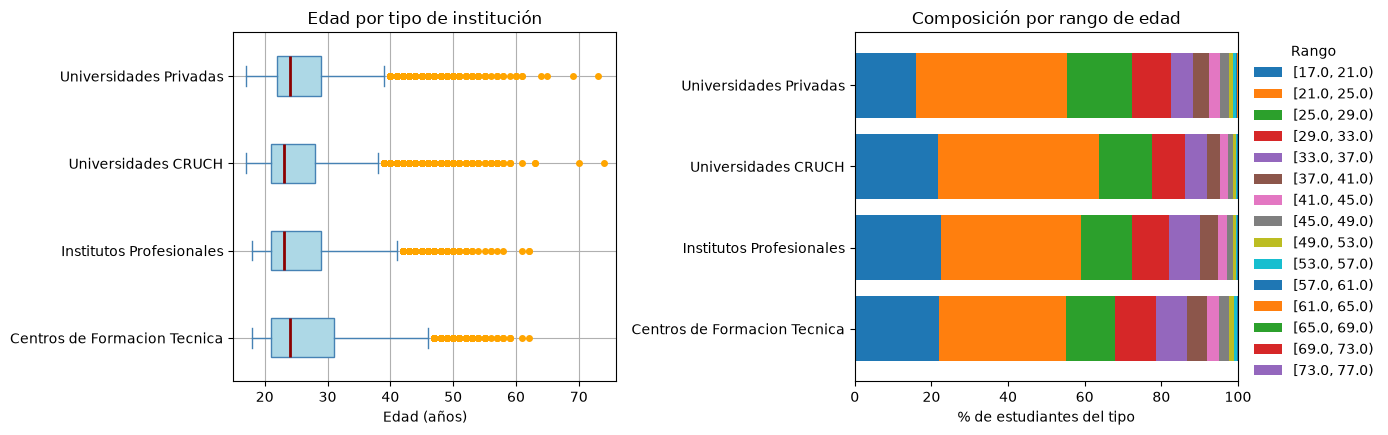

In [15]:
ct = pd.crosstab(
    df["TIPO DE INSTITUCION"],
    df["RANGO EDAD"]
)

ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

print("Perfil de edad dentro de cada tipo (%)")
display(ct_pct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

df.boxplot(
    column="EDAD",
    by="TIPO DE INSTITUCION",
    ax=axes[0],
    vert=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightblue",
        color="steelblue"
    ),
    whiskerprops=dict(
        color="steelblue"
    ),
    capprops=dict(
        color="steelblue"
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    flierprops=dict(
        marker="o",
        markerfacecolor="orange",
        markeredgecolor="orange",
        markersize=4
    )
)

axes[0].set_xlim(15, 76)
axes[0].set_ylabel("")
axes[0].set_xlabel("Edad (años)")
axes[0].set_title("Edad por tipo de institución")
axes[0].figure.suptitle("")


ct_pct.plot(
    kind="barh",
    stacked=True,
    ax=axes[1],
    width=0.8
)

axes[1].set_xlabel("% de estudiantes del tipo")
axes[1].set_ylabel("")
axes[1].set_title("Composición por rango de edad")
axes[1].set_xlim(0, 100)

axes[1].legend(
    title="Rango",
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

#### Interpretación  Tipo de institución × Edad

La distribución por rango de edad es similar entre los distintos tipos de institución. En todos los casos, el grupo más frecuente corresponde a estudiantes entre 21 y 25 años, seguido por el rango de 17 a 21 años.

Las Universidades CRUCH presentan la mayor concentración entre 21 y 25 años, con 42,0%, mientras que los CFT tienen una distribución algo más dispersa, con 33,2% en este rango y una mayor proporción de estudiantes entre 17 y 21 años (21,9%).

Las Universidades Privadas presentan una mayor proporción en el rango de 25 a 29 años (17,0%), siendo el valor más alto entre los cuatro tipos de institución.

En general, la mayoría de los estudiantes se concentra entre los 17 y 29 años, mientras que los rangos de edades superiores a 40 años representan porcentajes considerablemente menores.

### 4.3 Otros resúmenes

**resúmenes que contextualizan los datos: (a) año de ingreso de los estudiantes (2014–2021), (b) distribución por área del conocimiento y (c) jornada y modalidad.**

#### 4.3.1 Tabla resumen cantidad estudiante y año ingreso  (2014 y 2021).

In [16]:
ing = df["AÑO INGRESO"].value_counts().sort_index()
rec = ing.loc[2014:2021]

tabla_ingreso = pd.DataFrame({
    "Estudiantes": rec,
    "Porcentaje (%)": rec / len(df) * 100
})

display(tabla_ingreso.round(2))

,Estudiantes,Porcentaje (%)
AÑO INGRESO,,
2014,196,1.27
2015,328,2.12
2016,618,4.00
2017,1079,6.98
2018,1739,11.25
2019,2931,18.96
2020,3578,23.15
2021,4744,30.69


#### 4.3.2 Edad mediana según año de ingreso

In [17]:
tabla_edad_ingreso = (
    df.groupby("AÑO INGRESO")["EDAD"]
    .median()
    .loc[2014:2021]
    .to_frame("Edad mediana")
)

display(tabla_edad_ingreso)

,Edad mediana
AÑO INGRESO,
2014,27.0
2015,25.0
2016,24.0
2017,24.0
2018,23.0
2019,23.0
2020,22.0
2021,22.0


#### 4.3.3 Distribución por área del conocimiento

In [26]:
tabla_area = df["AREA CONOCIMIENTO"].value_counts().to_frame(
    "Frecuencia absoluta"
)

tabla_area["Frecuencia relativa (%)"] = (
    tabla_area["Frecuencia absoluta"] / len(df) * 100
)

display(tabla_area.round(2))

,Frecuencia absoluta,Frecuencia relativa (%)
AREA CONOCIMIENTO,,
Tecnologia,4131,26.72
Administracion y Comercio,3231,20.90
Salud,2835,18.34
Educacion,2118,13.70
Ciencias Sociales,1711,11.07
Derecho,865,5.60
Arte y Arquitectura,290,1.88
Humanidades,156,1.01
Ciencias Basicas,86,0.56


#### 4.3.4 Jornada 

In [18]:
tabla_jornada = (
    df["JORNADA"]
    .value_counts()
    .to_frame("Frecuencia")
)

tabla_jornada["Porcentaje (%)"] = (
    tabla_jornada["Frecuencia"] / len(df) * 100
)

display(tabla_jornada.round(2))

,Frecuencia,Porcentaje (%)
JORNADA,,
Diurno,9346,60.46
Vespertino,5828,37.70
Semipresencial,249,1.61
A Distancia,36,0.23


#### 4.3.5 Modalidad

In [19]:
tabla_modalidad = (
    df["MODALIDAD"]
    .value_counts()
    .to_frame("Frecuencia")
)

tabla_modalidad["Porcentaje (%)"] = (
    tabla_modalidad["Frecuencia"] / len(df) * 100
)

display(tabla_modalidad.round(2))

,Frecuencia,Porcentaje (%)
MODALIDAD,,
Presencial,15135,97.90
Semipresencial,288,1.86
No Presencial,36,0.23


### Interpretación de los otros resúmenes

**aqui**


---
# ÍTEM 2 Preguntas de investigación

**Agrupa la base en programas y verifica que cada programa tenga un único arancel. Deja listas las columnas `arancel`, `estudiantes`, `semestres` y `costo_total`.**

In [21]:
columnas_programa = [
    "NOMBRE CARRERA",
    "NOMBRE DE INSTITUCION",
    "TIPO DE INSTITUCION",
    "JORNADA",
    "MODALIDAD",
    "TIPO PLAN CARRERA",
    "NIVEL CARRERA",
    "AREA CONOCIMIENTO",
    "COMUNA SEDE"
]

programas = df.groupby(columnas_programa).agg(
    arancel=("VALOR ARANCEL (PESOS)", "median"),
    estudiantes=("ID", "count"),
    semestres=("DURACION TOTAL CARRERA (SEMESTRES)", "median")
).reset_index()

programas["costo_total"] = (
    programas["arancel"] * programas["semestres"] / 2
)

In [22]:
verificacion = df.groupby(columnas_programa)["VALOR ARANCEL (PESOS)"].nunique()

verificacion.value_counts()

VALOR ARANCEL (PESOS)
1    266
Name: count, dtype: int64

## Pregunta 1  ¿Hay áreas del conocimiento donde las carreras sean más caras?

**Criterio diseñado**

1. **Unidad:** programa (no estudiante), para no mezclar precio con demanda.
2. **Población comparable:** solo *Carreras Profesionales* con arancel > 0. Se excluyen técnicas (más cortas y baratas, y su presencia varía mucho entre áreas), magísteres y postítulos (otro nivel de formación).
3. **Medida:** **mediana** del arancel anual por área (robusta a valores extremos) y su **razón respecto de la mediana global** (1,00 = igual al conjunto).
4. **Contraste formal:** prueba de Kruskal-Wallis entre áreas (no supone normalidad), solo con áreas de ≥ 5 programas, más tamaño de efecto (ε²).
5. **Sensibilidad:** repetir el ranking con otras definiciones (incluye técnicas, ponderado por estudiantes, costo total de la carrera) y revisar si el resultado se mantiene dentro de un mismo tipo de institución.

In [23]:
prof = programas[
    (programas["NIVEL CARRERA"] == "Carreras Profesionales") &
    (programas["arancel"] > 0)
]

med_global = prof["arancel"].median()

print(
    f"Programas profesionales analizados: {len(prof):,} | "
    f"Mediana global: ${med_global:,.0f}"
)

t_area = (
    prof.groupby("AREA CONOCIMIENTO")
    .agg(
        programas=("arancel", "size"),
        estudiantes=("estudiantes", "sum"),
        mediana=("arancel", "median"),
        media=("arancel", "mean"),
        minimo=("arancel", "min"),
        maximo=("arancel", "max")
    )
    .sort_values("mediana", ascending=False)
)

t_area["razon_vs_mediana_global"] = (
    t_area["mediana"] / med_global
)

display(t_area.round(2))

Programas profesionales analizados: 168 | Mediana global: $2,164,000


,programas,estudiantes,mediana,media,minimo,maximo,razon_vs_mediana_global
AREA CONOCIMIENTO,,,,,,,
Salud,14,1867,3297500.0,3256785.71,2552000.0,4047000.0,1.52
Derecho,5,781,3275000.0,3172200.00,2350000.0,3995000.0,1.51
Agropecuaria,1,24,2933000.0,2933000.00,2933000.0,2933000.0,1.36
Ciencias Basicas,1,17,2481000.0,2481000.00,2481000.0,2481000.0,1.15
Arte y Arquitectura,3,264,2258000.0,2501000.00,2258000.0,2987000.0,1.04
Tecnologia,69,3156,2164000.0,2331275.36,1700000.0,3805000.0,1.00
Administracion y Comercio,35,1902,2112000.0,2250114.29,1240000.0,3533000.0,0.98
Educacion,23,1075,2106000.0,2060746.09,1528000.0,2857000.0,0.97
Ciencias Sociales,15,1536,2086000.0,2356853.33,1644000.0,3559000.0,0.96


### Interpretación

Salud presenta la mayor mediana de arancel, con $3.297.500, equivalente a 1,52 veces la mediana global.
Derecho ocupa el segundo lugar, con $3.275.000 y una razón de 1,51.
Agropecuaria también presenta un valor alto ($2.933.000), pero debe interpretarse con cautela porque solo tiene 1 programa.
Tecnología tiene una mediana de $2.164.000, prácticamente igual a la mediana global (razón = 1,00), y además cuenta con 69 programas, por lo que su resultado es más representativo.
Humanidades presenta la menor mediana, con $1.998.300, equivalente al 92% de la mediana global, aunque también tiene pocos programas (2).

Conclusión: sí se observan diferencias de costos entre las áreas del conocimiento. Salud y Derecho presentan los aranceles medianos más altos, mientras que Humanidades, Ciencias Sociales y Educación presentan valores inferiores a la mediana global. Sin embargo, las áreas con pocos programas deben interpretarse con cautela.

### Análisis del arancel anual de carreras profesionales según área del conocimiento

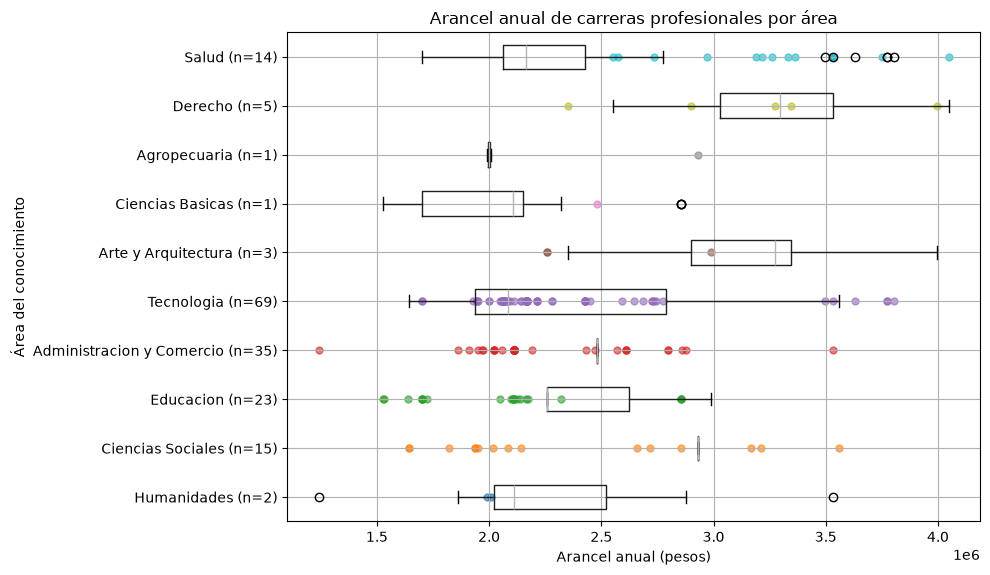

In [25]:
orden = t_area.sort_values("mediana").index

fig, ax = plt.subplots(figsize=(10, 6))

prof.boxplot(
    column="arancel",
    by="AREA CONOCIMIENTO",
    ax=ax,
    positions=range(len(orden)),
    vert=False
)

for i, area in enumerate(orden):
    datos = prof[prof["AREA CONOCIMIENTO"] == area]["arancel"]
    
    ax.scatter(
        datos,
        [i] * len(datos),
        alpha=0.6,
        s=25
    )

ax.set_yticks(range(len(orden)))
ax.set_yticklabels([
    f"{area} (n={len(prof[prof['AREA CONOCIMIENTO'] == area])})"
    for area in orden
])

ax.set_xlabel("Arancel anual (pesos)")
ax.set_ylabel("Área del conocimiento")
ax.set_title("Arancel anual de carreras profesionales por área")

ax.figure.suptitle("")
plt.tight_layout()
plt.show()

### Interpretacion del grafico anterior

**Determinar si existen diferencias en el costo de las carreras según el área del conocimiento y comprobar si las áreas con mayores costos se mantienen al utilizar distintos criterios de análisis.**

In [26]:
# A: Mediana de carreras profesionales
s_A = (
    prof.groupby("AREA CONOCIMIENTO")["arancel"]
    .median()
)

# B: Mediana incluyendo carreras técnicas
s_B = (
    programas[
        (programas["NIVEL CARRERA"].isin(
            ["Carreras Profesionales", "Carreras Tecnicas"]
        )) &
        (programas["arancel"] > 0)
    ]
    .groupby("AREA CONOCIMIENTO")["arancel"]
    .median()
)

# C: Mediana a nivel de estudiante
s_C = (
    df[
        (df["NIVEL CARRERA"] == "Carreras Profesionales") &
        (df["VALOR ARANCEL (PESOS)"] > 0)
    ]
    .groupby("AREA CONOCIMIENTO")["VALOR ARANCEL (PESOS)"]
    .median()
)

# D: Mediana del costo total de la carrera
s_D = (
    prof.groupby("AREA CONOCIMIENTO")["costo_total"]
    .median()
)

# Unir resultados
sens = pd.DataFrame({
    "A_Profesionales": s_A,
    "B_Incluye tecnicas": s_B,
    "C_Por estudiante": s_C,
    "D_Costo total": s_D
})

# Ordenar según el criterio A
sens = sens.loc[
    s_A.sort_values(ascending=False).index
]

display(sens.round(0))

,A_Profesionales,B_Incluye tecnicas,C_Por estudiante,D_Costo total
AREA CONOCIMIENTO,,,,
Salud,3297500.0,2736000.0,3217000.0,16487500.0
Derecho,3275000.0,3086500.0,3275000.0,18386500.0
Agropecuaria,2933000.0,2933000.0,2933000.0,14665000.0
Ciencias Basicas,2481000.0,1544000.0,2481000.0,12405000.0
Arte y Arquitectura,2258000.0,2258000.0,2987000.0,9032000.0
Tecnologia,2164000.0,2164000.0,2426000.0,8672000.0
Administracion y Comercio,2112000.0,2095000.0,2474000.0,8448000.0
Educacion,2106000.0,1700000.0,2106000.0,9742500.0
Ciencias Sociales,2086000.0,1984500.0,2719000.0,9114000.0


**Comparar el arancel de las carreras entre las distintas áreas del conocimiento, considerando por separado cada tipo de institución. Esto permite verificar si las diferencias de costo entre áreas se mantienen incluso cuando se comparan instituciones del mismo tipo.**

In [55]:
piv = prof.pivot_table(
    index="AREA CONOCIMIENTO",
    columns="TIPO DE INSTITUCION",
    values="arancel",
    aggfunc="median"
)

cnt = prof.pivot_table(
    index="AREA CONOCIMIENTO",
    columns="TIPO DE INSTITUCION",
    values="arancel",
    aggfunc="size"
).fillna(0).astype(int)

print("Mediana de arancel por área y tipo de institución")
display(piv.round(0))

print("Número de programas en cada celda")
display(cnt)

Mediana de arancel por área y tipo de institución


TIPO DE INSTITUCION,Institutos Profesionales,Universidades CRUCH,Universidades Privadas
AREA CONOCIMIENTO,,,
Administracion y Comercio,1998500.0,2608000.0,2112000.0
Agropecuaria,NaN,2933000.0,NaN
Arte y Arquitectura,2258000.0,2987000.0,NaN
Ciencias Basicas,NaN,2481000.0,NaN
Ciencias Sociales,1939000.0,2719000.0,2086000.0
Derecho,NaN,3446500.0,3275000.0
Educacion,1723000.0,2117500.0,1700000.0
Humanidades,NaN,1998300.0,NaN
Salud,NaN,3252500.0,3297500.0


Número de programas en cada celda


TIPO DE INSTITUCION,Institutos Profesionales,Universidades CRUCH,Universidades Privadas
AREA CONOCIMIENTO,,,
Administracion y Comercio,10,8,17
Agropecuaria,0,1,0
Arte y Arquitectura,2,1,0
Ciencias Basicas,0,1,0
Ciencias Sociales,3,5,7
Derecho,0,2,3
Educacion,1,12,10
Humanidades,0,2,0
Salud,0,8,6


### Respuesta — Pregunta 1

**Respuesta: sí. Salud y Derecho son las áreas más caras, cerca de 1,5 veces la mediana.**

**Sensibilidad:** El análisis muestra que la posición de las áreas de mayor costo es relativamente estable frente a los distintos criterios utilizados. En el criterio A, la mediana del arancel profesional alcanza **$3.297.500 en Salud** y **$3.275.000 en Derecho**, valores **52,3% y 51,3% superiores**, respectivamente, a la mediana global de $2.164.000.

En el criterio B, al incorporar carreras técnicas, **Derecho mantiene el primer lugar con $3.086.500**, mientras que Salud disminuye a **$2.736.000**, ocupando el tercer lugar. Esto representa una reducción de aproximadamente **17,0% para Salud** respecto del criterio A, mientras que Derecho disminuye un **5,8%**.

En el criterio C, calculado a nivel de estudiante, Salud presenta una mediana de **$3.217.000** y Derecho de **$3.275.000**, manteniéndose ambas entre las dos áreas con mayores valores.

Al considerar el costo total estimado de la carrera (criterio D), **Derecho alcanza $18.386.500 y Salud $16.487.500**, superando a Tecnología ($8.672.000) en aproximadamente **112,0% y 90,1%**, respectivamente. Por lo tanto, aunque el orden puede variar según el criterio utilizado, **Salud y Derecho presentan consistentemente los mayores niveles de costo**, respaldando la conclusión de que estas áreas se encuentran entre las más caras del conjunto analizado.


## Pregunta 2- ¿Qué influencia tiene la edad en el tipo de institución a la que ingresan los estudiantes?

**Criterio diseñado**

**Distribución de la muestra:** analizar la frecuencia y porcentaje de estudiantes según el tipo de institución, con el fin de conocer cómo se encuentra distribuida la muestra.

**Edad según tipo de institución:** comparar la media, mediana, moda y medidas de dispersión de la edad para identificar posibles diferencias entre los distintos tipos de institución.

**Distribución por rangos de edad:** construir una tabla cruzada entre tipo de institución y rango de edad, utilizando porcentajes para determinar en qué rangos se concentra la población de cada institución.

**Comparación visual:** utilizar un boxplot para comparar la distribución de las edades entre los tipos de institución, observando diferencias de posición, dispersión y posibles valores atípicos.

**Asociación y comprobación:** aplicar la prueba de Chi-cuadrado y V de Cramér para determinar si existe una asociación entre el tipo de institución y el rango de edad, y complementar el análisis revisando si los resultados se mantienen al considerar estudiantes de pregrado y la jornada.

### 1- Distribución de la muestra
#### Analizar la frecuencia y porcentaje de estudiantes según el tipo de institución, con el fin de conocer cómo se encuentra distribuida la muestra.


In [32]:
tabla_institucion = df.groupby("TIPO DE INSTITUCION").size().to_frame("Frecuencia")

tabla_institucion["Porcentaje (%)"] = (
    tabla_institucion["Frecuencia"] /
    tabla_institucion["Frecuencia"].sum() * 100
).round(1)

display(tabla_institucion)

,Frecuencia,Porcentaje (%)
TIPO DE INSTITUCION,,
Centros de Formacion Tecnica,3115,20.2
Institutos Profesionales,3118,20.2
Universidades CRUCH,6644,43.0
Universidades Privadas,2582,16.7


La muestra está compuesta principalmente por estudiantes de Universidades CRUCH (43,0%), mientras que los Centros de Formación Técnica (20,2%) e Institutos Profesionales (20,2%) presentan una participación similar. Las Universidades Privadas (16,7%) representan la menor proporción de la muestra.

### 2- Edad según tipo de institución
#### comparar la media, mediana, moda y medidas de dispersión de la edad para identificar posibles diferencias entre los distintos tipos de institución.

In [33]:
tabla_edad = df.groupby("TIPO DE INSTITUCION")["EDAD"].agg(
    Media="mean",
    Mediana="median",
    Moda=lambda x: x.mode().iloc[0],
    Desviacion_Estandar="std",
    Minimo="min",
    Maximo="max"
)

display(tabla_edad.round(2))

,Media,Mediana,Moda,Desviacion_Estandar,Minimo,Maximo
TIPO DE INSTITUCION,,,,,,
Centros de Formacion Tecnica,26.79,24.0,19,8.17,18,62
Institutos Profesionales,25.89,23.0,19,7.24,18,62
Universidades CRUCH,25.33,23.0,19,6.88,17,74
Universidades Privadas,26.68,24.0,24,7.80,17,73


Los CFT presentan la mayor edad promedio (26,79 años), seguidos por las universidades privadas (26,68), mientras que las universidades CRUCH presentan el promedio más bajo (25,33). La mediana confirma una diferencia similar, aunque las diferencias entre instituciones son relativamente pequeñas. La edad más frecuente es 19 años, excepto en las universidades privadas, donde es 24 años. La dispersión es mayor en los CFT y menor en las universidades CRUCH.

### Distribución por rangos de edad
#### construir una tabla cruzada entre tipo de institución y rango de edad, utilizando porcentajes para determinar en qué rangos se concentra la población de cada institución.

In [35]:
tabla_rangos = pd.crosstab(
    df["TIPO DE INSTITUCION"],
    df["RANGO EDAD"],
    normalize="index"
) * 100

display(tabla_rangos.round(1))

RANGO EDAD,"[17.0, 21.0)","[21.0, 25.0)","[25.0, 29.0)","[29.0, 33.0)","[33.0, 37.0)","[37.0, 41.0)","[41.0, 45.0)","[45.0, 49.0)","[49.0, 53.0)","[53.0, 57.0)","[57.0, 61.0)","[61.0, 65.0)","[65.0, 69.0)","[69.0, 73.0)","[73.0, 77.0)"
TIPO DE INSTITUCION,,,,,,,,,,,,,,,
Centros de Formacion Tecnica,21.9,33.2,12.7,10.9,7.9,5.2,3.3,2.4,1.3,0.7,0.3,0.1,0.0,0.0,0.0
Institutos Profesionales,22.5,36.4,13.4,9.7,8.0,4.7,2.4,1.6,0.8,0.2,0.1,0.1,0.0,0.0,0.0
Universidades CRUCH,21.6,42.0,13.8,8.6,5.7,3.5,2.2,1.3,0.6,0.3,0.2,0.0,0.0,0.0,0.0
Universidades Privadas,16.0,39.3,17.0,10.3,5.5,4.2,3.0,2.3,1.1,0.7,0.3,0.1,0.0,0.0,0.0


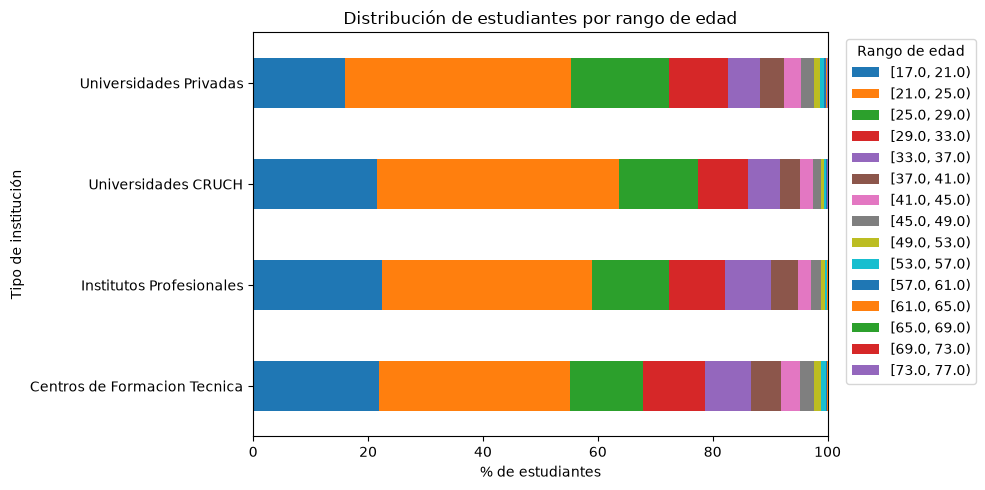

In [36]:
tabla_rangos.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 5)
)

plt.xlabel("% de estudiantes")
plt.ylabel("Tipo de institución")
plt.title("Distribución de estudiantes por rango de edad")
plt.xlim(0, 100)

plt.legend(
    title="Rango de edad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

La mayor concentración de estudiantes se encuentra entre los 21 y 25 años en todos los tipos de institución, especialmente en las Universidades CRUCH (42,0%). Los CFT presentan una mayor proporción de estudiantes de 29 años o más, mientras que las universidades muestran una concentración relativamente mayor en edades jóvenes. En general, la edad presenta diferencias entre instituciones, pero no son muy marcadas.

### 4- Comparación visual
#### Utilizar un boxplot para comparar la distribución de las edades entre los tipos de institución, observando diferencias de posición, dispersión y posibles valores atípicos.

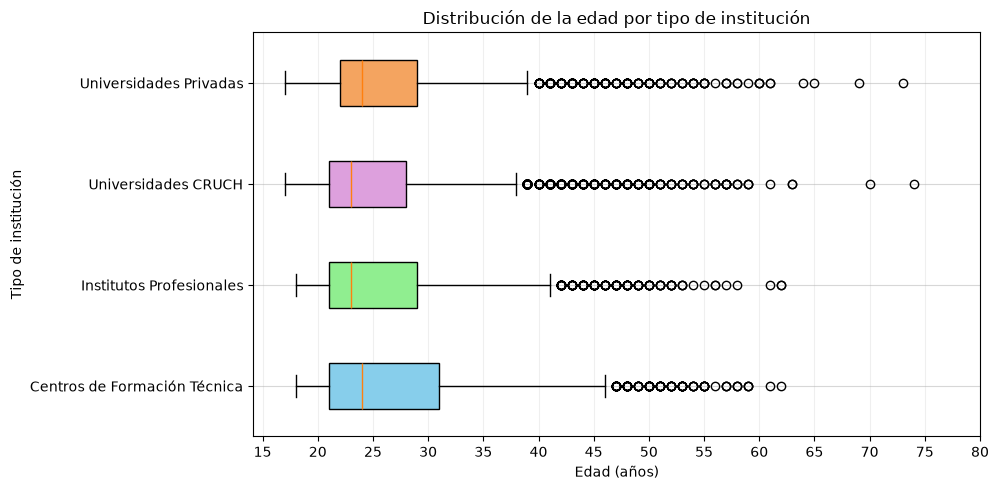

In [51]:
import matplotlib.pyplot as plt

grupos = [
    df[df["TIPO DE INSTITUCION"] == "Centros de Formacion Tecnica"]["EDAD"],
    df[df["TIPO DE INSTITUCION"] == "Institutos Profesionales"]["EDAD"],
    df[df["TIPO DE INSTITUCION"] == "Universidades CRUCH"]["EDAD"],
    df[df["TIPO DE INSTITUCION"] == "Universidades Privadas"]["EDAD"]
]

nombres = [
    "Centros de Formación Técnica",
    "Institutos Profesionales",
    "Universidades CRUCH",
    "Universidades Privadas"
]

colores = ["skyblue", "lightgreen", "plum", "sandybrown"]

fig, ax = plt.subplots(figsize=(10, 5))

box = ax.boxplot(
    grupos,
    tick_labels=nombres,
    patch_artist=True,
    orientation="horizontal"
)

for caja, color in zip(box["boxes"], colores):
    caja.set_facecolor(color)

ax.set_xlabel("Edad (años)")
ax.set_ylabel("Tipo de institución")
ax.set_title("Distribución de la edad por tipo de institución")

plt.tight_layout()
ax.set_xticks(range(15, 81, 5))
plt.grid(axis="x", alpha=0.2)
plt.grid(axis="y", alpha=0.5)
plt.show()

El boxplot muestra que las Universidades CRUCH presentan la menor mediana de edad y menor dispersión, mientras que los CFT presentan una mayor dispersión y una mediana ligeramente superior. Las Universidades Privadas e Institutos Profesionales muestran una distribución intermedia. Además, se observan valores atípicos de edades mayores en los distintos tipos de institución, especialmente en CFT y universidades.

### 5- Jornada
#### Objetivo: revisar si la edad se relaciona con la jornada (diurna o vespertina) según el tipo de institución.

In [55]:
tabla_jornada = df.groupby(
    ["TIPO DE INSTITUCION", "JORNADA"]
)["EDAD"].agg(
    Media="mean",
    Mediana="median",
    Frecuencia="count"
)

display(tabla_jornada.round(2))

Media  Mediana  Frecuencia
TIPO DE INSTITUCION          JORNADA                                   
Centros de Formacion Tecnica Diurno          24.41     22.0        1773
                             Vespertino      29.92     28.0        1342
Institutos Profesionales     Diurno          23.15     22.0        1536
                             Vespertino      28.54     27.0        1582
Universidades CRUCH          A Distancia     38.61     39.0          36
                             Diurno          23.25     22.0        4523
                             Semipresencial  39.50     36.5          12
                             Vespertino      29.56     28.0        2073
Universidades Privadas       Diurno          23.24     23.0        1514
                             Semipresencial  30.93     29.0         237
                             Vespertino      31.75     29.0         831

In [57]:
concentracion_jovenes = pd.crosstab(
    df["TIPO DE INSTITUCION"],
    df["TRAMO_EDAD"],
    normalize="index"
) * 100

display(concentracion_jovenes.round(2))

TRAMO_EDAD,≤ 19,20–24,25–29,≥ 30
TIPO DE INSTITUCION,,,,
Centros de Formacion Tecnica,16.47,38.62,17.34,27.58
Institutos Profesionales,16.87,42.05,17.64,23.44
Universidades CRUCH,16.26,47.41,17.52,18.81
Universidades Privadas,11.12,44.23,21.57,23.08


Concentración de jóvenes: Las Universidades CRUCH presentan la mayor concentración de estudiantes jóvenes, con un 63,67% de estudiantes de 24 años o menos. Esto coincide con su alta proporción de estudiantes en jornada diurna, que presenta una edad promedio menor que la jornada vespertina. En cambio, los CFT e IP presentan una mayor presencia relativa de estudiantes de 30 años o más, especialmente los CFT con un 27,58%.

### Respuesta  Pregunta 2

**Respuesta: la edad se relaciona con el tipo de institución, pero su influencia es débil.**

Los CFT presentan la mayor edad promedio (26,79 años) y la mayor proporción de estudiantes de 30 años o más (27,58%), mientras que las Universidades CRUCH presentan la menor edad promedio (25,33 años) y la mayor concentración de estudiantes jóvenes, con un 63,67% de estudiantes de 24 años o menos.

La jornada puede ayudar a comprender parte de estas diferencias. Los estudiantes diurnos presentan una mediana de 22 años, mientras que los vespertinos alcanzan 28 años. Además, la jornada vespertina tiene mayor presencia en los IP (50,74%) y CFT (43,08%) que en las Universidades CRUCH (31,20%) y Privadas (32,18%). Esto es consistente con una mayor presencia de estudiantes de mayor edad en CFT e IP.

En conclusión, **existe una asociación entre edad y tipo de institución, pero es pequeña**. Las diferencias observadas parecen estar relacionadas, en parte, con la distribución de estudiantes jóvenes y con la jornada de estudio, aunque la base de datos no permite establecer una relación causal.


## Pregunta 3  ¿Hay carreras sustantivamente más caras que la mayoría? ¿Cómo se explica?

**Criterio diseñado**

**Definición:** identificar los aranceles excepcionalmente altos mediante la regla de Tukey, considerando los programas de pregrado con arancel mayor que 0.

**Magnitud:** determinar cuántos programas presentan aranceles atípicamente altos y cuánto superan la mediana.
**Explicación:** comparar estos programas con el resto según tipo de institución, área, duración y nivel de formación, buscando posibles factores asociados al mayor arancel.

**Contexto regional:** relacionar los resultados con la oferta de instituciones y carreras de la Región de Tarapacá.

### Definición
#### Identificar los aranceles excepcionalmente altos mediante la regla de Tukey, considerando los programas de pregrado con arancel mayor que 0.

In [59]:
df_pregrado = df[
    (df["VALOR ARANCEL (PESOS)"] > 0) &
    (df["NIVEL DE ESTUDIO CARRERA"].str.contains("pregrado", case=False, na=False))
].copy()

q1 = df_pregrado["VALOR ARANCEL (PESOS)"].quantile(0.25)
q3 = df_pregrado["VALOR ARANCEL (PESOS)"].quantile(0.75)

iqr = q3 - q1

limite_superior = q3 + 1.5 * iqr

print("Q3:", q3)
print("Límite superior:", limite_superior)

Q3: 2775000.0
Límite superior: 4066500.0


In [61]:
carreras_caras = df_pregrado[
    df_pregrado["VALOR ARANCEL (PESOS)"] > limite_superior
].sort_values("VALOR ARANCEL (PESOS)", ascending=False)

display(
    carreras_caras[
        ["NOMBRE CARRERA", "NOMBRE DE INSTITUCION",
         "TIPO DE INSTITUCION", "VALOR ARANCEL (PESOS)"]
    ]
)

,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,VALOR ARANCEL (PESOS)


In [64]:
df_pregrado = df[
    (df["NIVEL DE ESTUDIO CARRERA"] == "Pregrado") &
    (df["VALOR ARANCEL (PESOS)"] > 0)
].copy()

print("Cantidad de registros:", len(df_pregrado))

Cantidad de registros: 15321


In [66]:
q1 = df_pregrado["VALOR ARANCEL (PESOS)"].quantile(0.25)
q3 = df_pregrado["VALOR ARANCEL (PESOS)"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Límite superior:", limite_superior)

Q1: 1914000.0
Q3: 2775000.0
IQR: 861000.0
Límite superior: 4066500.0


In [67]:
carreras_caras = df_pregrado[
    df_pregrado["VALOR ARANCEL (PESOS)"] > limite_superior
]

print("Cantidad de valores atípicos:", len(carreras_caras))

display(
    carreras_caras[
        ["NOMBRE CARRERA", "NOMBRE DE INSTITUCION",
         "TIPO DE INSTITUCION", "VALOR ARANCEL (PESOS)"]
    ]
)

Cantidad de valores atípicos: 0


,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,VALOR ARANCEL (PESOS)


In [68]:
top_aranceles = df_pregrado.sort_values(
    "VALOR ARANCEL (PESOS)",
    ascending=False
).head(10)

display(
    top_aranceles[
        ["NOMBRE CARRERA",
         "NOMBRE DE INSTITUCION",
         "TIPO DE INSTITUCION",
         "VALOR ARANCEL (PESOS)"]
    ]
)

,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,VALOR ARANCEL (PESOS)
2721,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
5042,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
13182,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
8939,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
8563,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
3057,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
3103,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
3122,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
8813,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
1323,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000


In [69]:
top_carreras = (
    df_pregrado
    .groupby(
        ["NOMBRE CARRERA", "NOMBRE DE INSTITUCION", "TIPO DE INSTITUCION"]
    )["VALOR ARANCEL (PESOS)"]
    .max()
    .sort_values(ascending=False)
    .head(10)
)

display(top_carreras.reset_index())

,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,VALOR ARANCEL (PESOS)
0,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000
1,DERECHO,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3995000
2,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3805000
3,INGENIERIA CIVIL ELECTRICA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3775000
4,INGENIERIA CIVIL ELECTRICA CON MENCION EN CONT...,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3775000
5,TECNOLOGIA MEDICA,UNIVERSIDAD SANTO TOMAS,Universidades Privadas,3749000
6,INGENIERIA CIVIL EN INFORMATICA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3631000
7,PSICOLOGIA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3559000
8,KINESIOLOGIA Y REHABILITACION,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3533000
9,ENFERMERIA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3533000


In [72]:
tabla_top = tabla_top[
    tabla_top["NOMBRE CARRERA"] != "Veces_mediana"
]

display(tabla_top)

,NOMBRE CARRERA,NOMBRE DE INSTITUCION,TIPO DE INSTITUCION,VALOR ARANCEL (PESOS),Veces_mediana
0,ODONTOLOGIA,UNIVERSIDAD ARTURO PRAT,Universidades CRUCH,4047000,1.86
1,DERECHO,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3995000,1.84
2,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3805000,1.75
3,INGENIERIA CIVIL ELECTRICA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3775000,1.74
4,INGENIERIA CIVIL ELECTRICA CON MENCION EN CONT...,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3775000,1.74
5,TECNOLOGIA MEDICA,UNIVERSIDAD SANTO TOMAS,Universidades Privadas,3749000,1.73
6,INGENIERIA CIVIL EN INFORMATICA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3631000,1.67
7,PSICOLOGIA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3559000,1.64
8,KINESIOLOGIA Y REHABILITACION,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3533000,1.63
9,ENFERMERIA,UNIVERSIDAD DE TARAPACA,Universidades CRUCH,3533000,1.63


In [73]:
tabla_tipo_arancel = df_pregrado.groupby(
    "TIPO DE INSTITUCION"
)["VALOR ARANCEL (PESOS)"].agg(
    Media="mean",
    Mediana="median",
    Maximo="max"
)

display(tabla_tipo_arancel.round(0))

,Media,Mediana,Maximo
TIPO DE INSTITUCION,,,
Centros de Formacion Tecnica,1710470.0,1627000.0,2570000
Institutos Profesionales,2126910.0,2112000.0,2570000
Universidades CRUCH,2593378.0,2671000.0,4047000
Universidades Privadas,2654727.0,3167000.0,3749000


In [74]:
tabla_area_arancel = df_pregrado.groupby(
    "AREA CONOCIMIENTO"
)["VALOR ARANCEL (PESOS)"].agg(
    Media="mean",
    Mediana="median",
    Maximo="max"
).sort_values("Media", ascending=False)

display(tabla_area_arancel.round(0))

,Media,Mediana,Maximo
AREA CONOCIMIENTO,,,
Derecho,3081987.0,3275000.0,3995000
Agropecuaria,2933000.0,2933000.0,2933000
Arte y Arquitectura,2657693.0,2987000.0,2987000
Salud,2642443.0,2736000.0,4047000
Ciencias Sociales,2443999.0,2142000.0,3559000
Tecnologia,2367112.0,2214000.0,3805000
Administracion y Comercio,2103976.0,2095000.0,3533000
Educacion,1784962.0,1700000.0,2857000
Humanidades,1753023.0,1744200.0,2007600


In [75]:
tabla_duracion_arancel = df_pregrado.groupby(
    "DURACION PLAN DE ESTUDIO (SEMESTRES)"
)["VALOR ARANCEL (PESOS)"].agg(
    Media="mean",
    Mediana="median",
    Maximo="max",
    Cantidad="count"
).sort_index()

display(tabla_duracion_arancel.round(0))

,Media,Mediana,Maximo,Cantidad
DURACION PLAN DE ESTUDIO (SEMESTRES),,,,
2,2197838.0,2086000.0,2432000,99
3,1700000.0,1700000.0,1700000,3
4,2189266.0,2170000.0,2570000,863
5,1498233.0,1544000.0,2164000,3810
6,1700000.0,1700000.0,1700000,33
7,1393333.0,1240000.0,1700000,6
8,2174791.0,2164000.0,3533000,3864
9,2309901.0,2189000.0,2857000,667
10,2878745.0,2797000.0,3995000,5083


In [76]:
tabla_acreditacion_arancel = df_pregrado.groupby(
    "AÑOS DE ACREDITACION"
)["VALOR ARANCEL (PESOS)"].agg(
    Media="mean",
    Mediana="median",
    Maximo="max",
    Cantidad="count"
).sort_index()

display(tabla_acreditacion_arancel.round(0))

,Media,Mediana,Maximo,Cantidad
AÑOS DE ACREDITACION,,,,
3.0,2125221.0,2112000.0,2432000,565
4.0,2569431.0,2719000.0,4047000,6903
5.0,2376670.0,1975000.0,3995000,3758
6.0,2266505.0,2170000.0,2570000,1769
7.0,2225481.0,2164000.0,2570000,933


In [77]:
tabla_comuna = df_pregrado.groupby(
    "COMUNA SEDE"
).agg(
    Instituciones=("NOMBRE DE INSTITUCION", "nunique"),
    Carreras=("NOMBRE CARRERA", "nunique"),
    Matriculas=("ID", "count")
).sort_values("Matriculas", ascending=False)

display(tabla_comuna)

,Instituciones,Carreras,Matriculas
COMUNA SEDE,,,
Iquique,9,153,14353
Alto Hospicio,1,7,968


In [78]:
tabla_nivel_arancel = df.groupby(
    "NIVEL DE ESTUDIO CARRERA"
)["VALOR ARANCEL (PESOS)"].agg(
    Media="mean",
    Mediana="median",
    Maximo="max",
    Cantidad="count"
)

display(tabla_nivel_arancel.round(0))

,Media,Mediana,Maximo,Cantidad
NIVEL DE ESTUDIO CARRERA,,,,
Postgrado,3518348.0,3245000.0,4847000,123
Postitulo,999840.0,999840.0,999840,15
Pregrado,2329188.0,2170000.0,4047000,15321


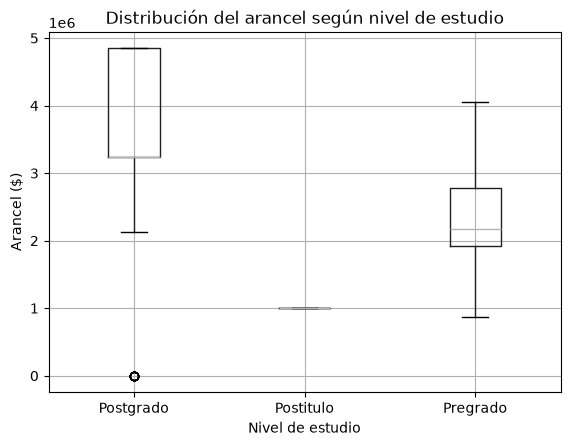

In [79]:
import matplotlib.pyplot as plt

df.boxplot(
    column="VALOR ARANCEL (PESOS)",
    by="NIVEL DE ESTUDIO CARRERA"
)

plt.title("Distribución del arancel según nivel de estudio")
plt.suptitle("")
plt.xlabel("Nivel de estudio")
plt.ylabel("Arancel ($)")
plt.show()

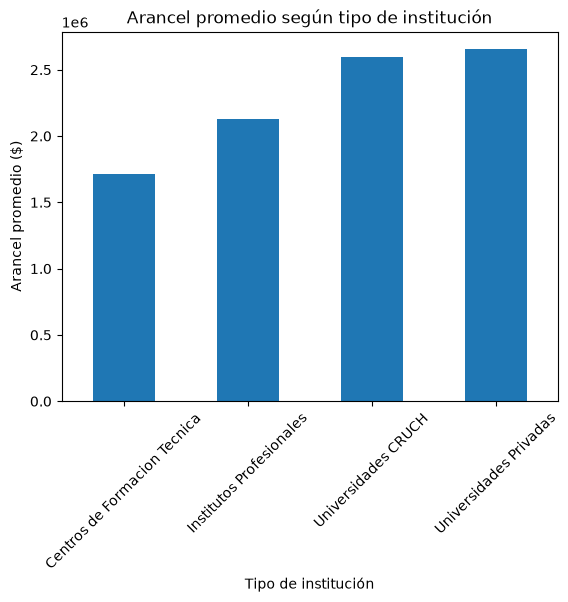

In [80]:
tabla_tipo_arancel["Media"].plot(kind="bar")

plt.title("Arancel promedio según tipo de institución")
plt.xlabel("Tipo de institución")
plt.ylabel("Arancel promedio ($)")
plt.xticks(rotation=45)
plt.show()

Sí existen carreras con aranceles considerablemente superiores a la mayoría, aunque no necesariamente constituyen valores atípicos según el criterio de Tukey. Para los programas de pregrado con arancel registrado, la mediana es de $2.170.000 y el límite superior de Tukey es $4.066.500. El arancel máximo alcanza $4.047.000, por lo que no supera dicho límite.

A pesar de esto, existen programas con aranceles muy superiores a la mediana. Entre los 10 más caros destacan Odontología de la Universidad Arturo Prat ($4.047.000), Derecho de la Universidad de Tarapacá ($3.995.000) e Ingeniería Civil Industrial de la Universidad de Tarapacá ($3.805.000). Odontología alcanza 1,86 veces la mediana del pregrado.

Al analizar los factores asociados al arancel, se observan diferencias según el tipo de institución. Los CFT presentan la menor media ($1.710.470), seguidos por los IP ($2.126.910), mientras que las universidades presentan valores superiores: $2.593.378 en universidades CRUCH y $2.654.727 en universidades privadas.

También existe una diferencia según el área de conocimiento. Derecho presenta la mayor media ($3.081.987), seguido de Agropecuaria ($2.933.000), Arte y Arquitectura ($2.657.693) y Salud ($2.642.443). Salud, además, contiene el arancel máximo de la base debido a Odontología.

La duración de la carrera muestra uno de los patrones más claros: los programas de mayor duración tienden a presentar aranceles más elevados. Las carreras de 5 semestres tienen una media de aproximadamente $1.498.000, mientras que las de 10, 11 y 12 semestres alcanzan aproximadamente $2.879.000, $3.421.000 y $3.782.000, respectivamente.

El nivel de estudio también presenta diferencias importantes. Los postgrados tienen una mediana de $3.245.000, superior a los $2.170.000 del pregrado, y alcanzan un máximo de $4.847.000. Los postítulos, en cambio, presentan una mediana de $999.840. Debido al reducido número de registros de postgrado y postítulo, estas diferencias deben interpretarse con cautela. Por esta razón, resulta adecuado analizar los postgrados por separado del pregrado.

En cuanto a la acreditación, no se observa una relación directa con el arancel: las instituciones con 4 años de acreditación presentan una media de $2.569.431, mientras que aquellas con 7 años presentan $2.225.481. Por lo tanto, una mayor acreditación no implica necesariamente un mayor arancel.

Finalmente, la oferta está fuertemente concentrada territorialmente en Iquique, que reúne 9 instituciones, 153 carreras y 14.353 matrículas, mientras que Alto Hospicio registra 1 institución, 7 carreras y 968 matrículas.